In [2]:
# Import Required libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report

In [4]:
#Load the Iris Dataset
iris = load_iris()

X = iris.data
y = iris.target
print("Feature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)

print("\nShape of dataset:",X.shape)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Shape of dataset: (150, 4)


In [5]:
#Convert data to binary Classification
y_binary = (y != 0).astype(int)

print("Binary labels:")
print(np.unique(y_binary,return_counts=True))

Binary labels:
(array([0, 1]), array([ 50, 100]))


In [6]:
#Select Two Features for Visualization
X_two = X[:, [2,3]]

In [7]:
#Split Training and Testing Data
X_train,X_test,y_train,y_test = train_test_split(
    X_two,y_binary,test_size=0.2,stratify=y_binary,random_state=42)

In [8]:
#Standardize the Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
#Train the linear SVM
linear_svm = SVC(
    kernel='linear',
    C=1.0
)
linear_svm.fit(X_train_scaled,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [13]:
#Make predictions
y_pred = linear_svm.predict(X_test_scaled)

accuracy = accuracy_score(y_test,y_pred)

print("Accuracy:",accuracy)
print("\nClassification Report:")
print(classification_report(y_test,y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



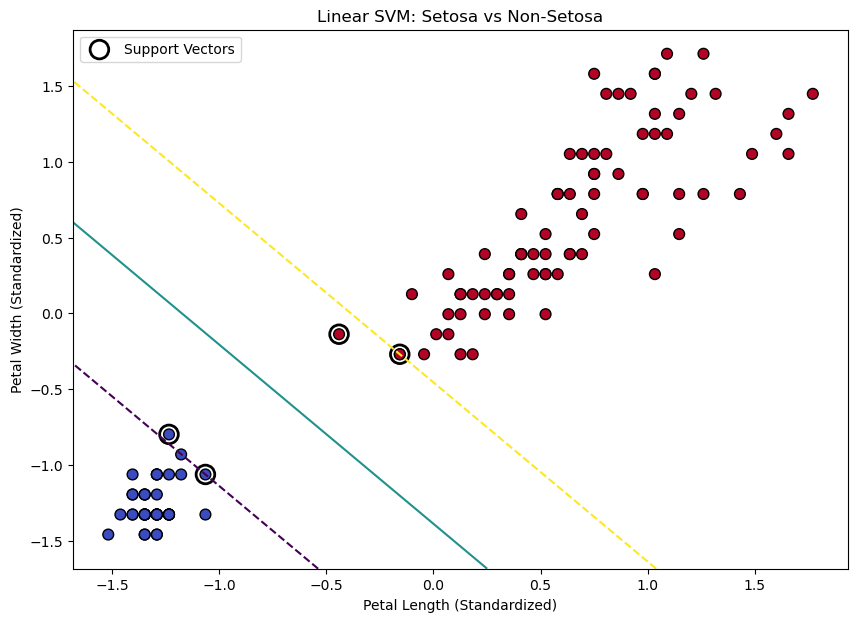

In [14]:
#Visualize Decision Boundary,Margins and support Vectors
plt.figure(figsize=(10,7))

#plot training points
plt.scatter(
    X_train_scaled[:,0],
    X_train_scaled[:,1],
    c=y_train,
    s=60,
    cmap='coolwarm',
    edgecolors='k'
)
#Create grid
ax = plt.gca()

xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0],xlim[1],200)
yy = np.linspace(xlim[0],ylim[1],200)

YY,XX = np.meshgrid(yy,xx)

xy = np.vstack([XX.ravel(),YY.ravel()]).T

#Calculate decision function
Z = linear_svm.decision_function(xy)

Z = Z.reshape(XX.shape)

#Draw decision boundary and margins
ax.contour(
    XX,
    YY,
    Z,
    levels=[-1,0,1],
    linestyles=['--','-','--']
)

#Highlight support vectors
ax.scatter(
    linear_svm.support_vectors_[:,0],
    linear_svm.support_vectors_[:,1],
    s=180,
    facecolors='none',
    edgecolors='black',
    linewidth=2,
    label='Support Vectors'
)

plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")
plt.title("Linear SVM: Setosa vs Non-Setosa")

plt.legend()
plt.show()

In [16]:
#Use all 4 features and the original 3 class target
X_full = iris.data
y_full = iris.target

X_train_full,X_test_full,y_train_full,y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)
#Scale the features
scaler_full = StandardScaler()

X_train_full = scaler_full.fit_transform(X_train_full)
X_test_full = scaler_full.transform(X_test_full)

In [17]:
#Create Linear, Polynomial and RBF SVM Models
models = {
    "Linear": SVC(kernel="linear",C=1.0),
    "Polyomial":SVC(kernel="poly",degree=3,C=1.0),
    "RBF":SVC(kernel="rbf",C=1.0,gamma="scale")
}

In [19]:
#Train and Compare
results = {}

for name,model in models.items():
    model.fit(X_train_full,y_train_full)
    y_pred = model.predict(X_test_full)
    accuracy = accuracy_score(y_test_full,y_pred)
    results[name] = accuracy
    
    print(f"\n{name} Kernel")
    print("-"*30)
    print("Accuracy:",accuracy)

    print(
        classification_report(
            y_test_full,
            y_pred,
            target_names=iris.target_names
        )
    )


Linear Kernel
------------------------------
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Polyomial Kernel
------------------------------
Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.77      1.00      0.87        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30


RBF Kernel
------------------------------
Accuracy: 0.9666666666666667
              precision    recall  f1-score